# Data Visualisation Fundamentals

Practice exercises with **Matplotlib**, **Seaborn** and **Plotly** on synthetic data.
Each section recreates a common chart type and the question it answers.

| Section | Chart types | Libraries |
|---|---|---|
| 1. Distributions | histogram + KDE, violin plot, box plot | Seaborn |
| 2. Categorical comparisons | bar, grouped bar, stacked bar | Seaborn, Pandas |
| 3. Relationships | scatter (with a third dimension), heatmap | Seaborn |
| 4. Time series | line chart | Matplotlib |
| 5. Interactive charts | line, scatter matrix, faceted histogram, bubble chart | Plotly Express |

> All data is randomly generated (fixed seeds), so every result is reproducible.
> The interactive Plotly charts (section 5) render when you run the notebook locally.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook"

## 1. Distributions

### Normal vs. skewed distribution

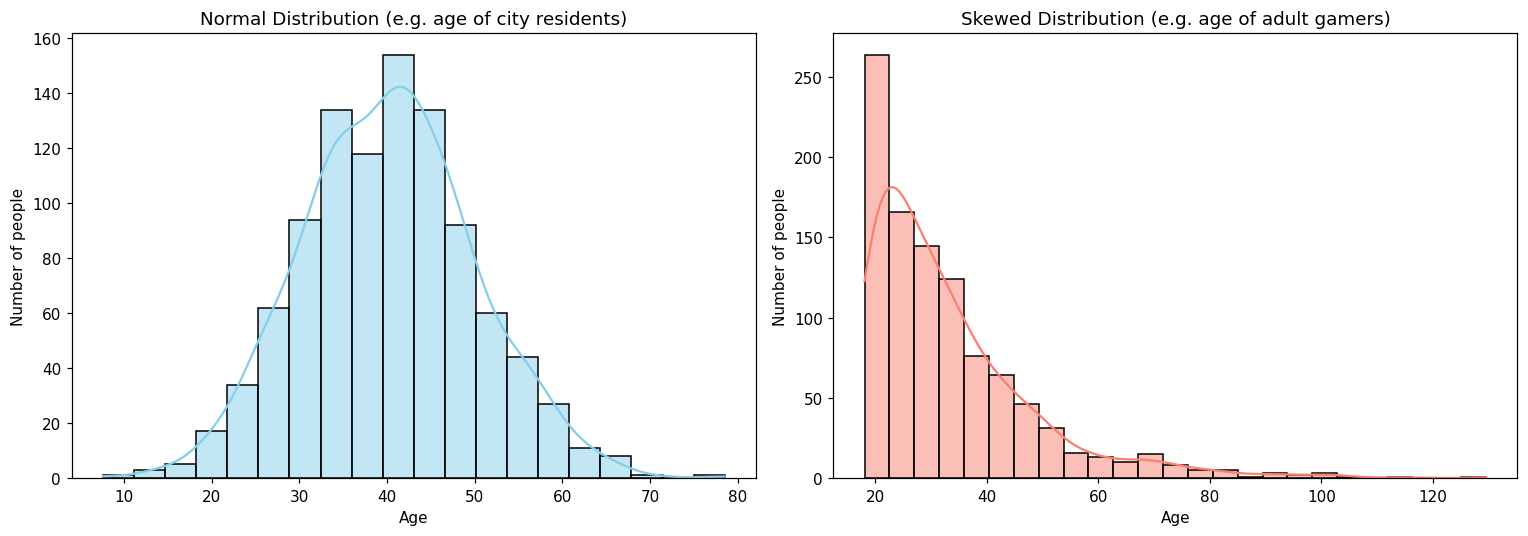

In [2]:
# Generate data
np.random.seed(42)
age_normal = np.random.normal(loc=40, scale=10, size=1000)  # normal distribution
age_skewed = np.random.exponential(scale=15, size=1000) + 18  # right-skewed distribution

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: normal distribution
sns.histplot(age_normal, bins=20, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Normal Distribution (e.g. age of city residents)')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Number of people')

# Plot 2: skewed distribution
sns.histplot(age_skewed, bins=25, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Skewed Distribution (e.g. age of adult gamers)')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Number of people')

plt.tight_layout()
plt.show()

### Four common distribution shapes

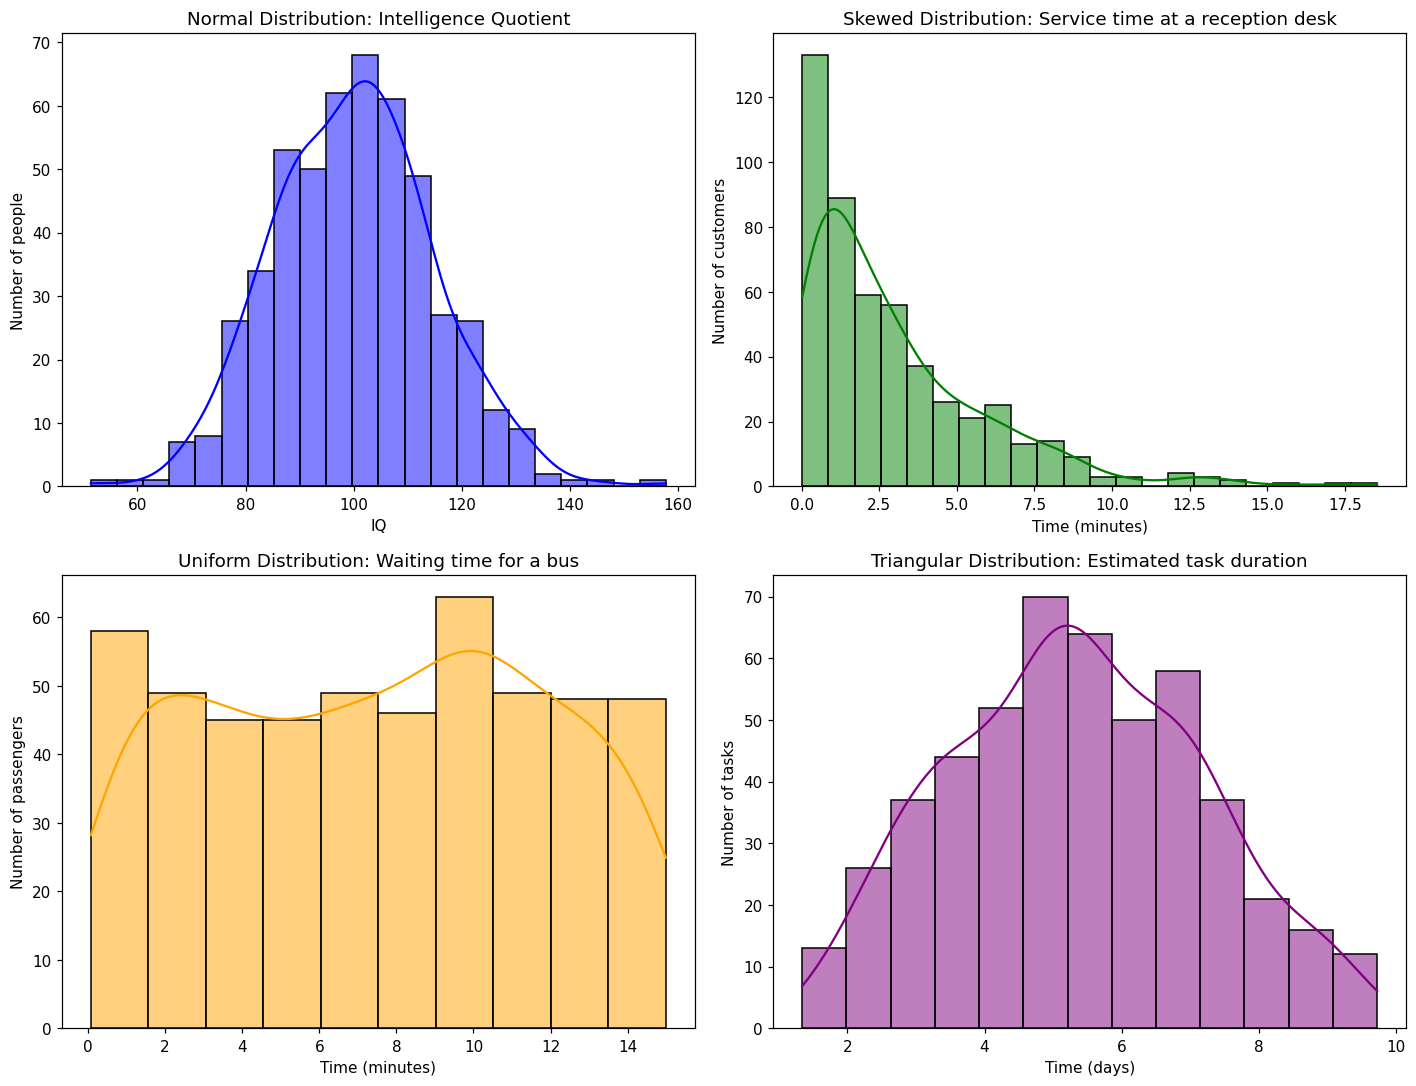

In [3]:
np.random.seed(42)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# 1. Normal distribution (IQ)
iq_data = np.random.normal(loc=100, scale=15, size=500)
sns.histplot(iq_data, ax=axes[0, 0], color='blue', kde=True)
axes[0, 0].set_title('Normal Distribution: Intelligence Quotient')
axes[0, 0].set_xlabel('IQ')
axes[0, 0].set_ylabel('Number of people')

# 2. Skewed distribution (waiting time)
service_time = np.random.exponential(scale=3, size=500)
sns.histplot(service_time, ax=axes[0, 1], color='green', kde=True)
axes[0, 1].set_title('Skewed Distribution: Service time at a reception desk')
axes[0, 1].set_xlabel('Time (minutes)')
axes[0, 1].set_ylabel('Number of customers')

# 3. Uniform distribution (bus)
bus_wait = np.random.uniform(low=0, high=15, size=500)
sns.histplot(bus_wait, ax=axes[1, 0], color='orange', kde=True)
axes[1, 0].set_title('Uniform Distribution: Waiting time for a bus')
axes[1, 0].set_xlabel('Time (minutes)')
axes[1, 0].set_ylabel('Number of passengers')

# 4. Triangular distribution (IT project)
task_time = np.random.triangular(left=1, mode=5, right=10, size=500)
sns.histplot(task_time, ax=axes[1, 1], color='purple', kde=True)
axes[1, 1].set_title('Triangular Distribution: Estimated task duration')
axes[1, 1].set_xlabel('Time (days)')
axes[1, 1].set_ylabel('Number of tasks')

plt.tight_layout()
plt.show()

### Box plot: spotting outliers

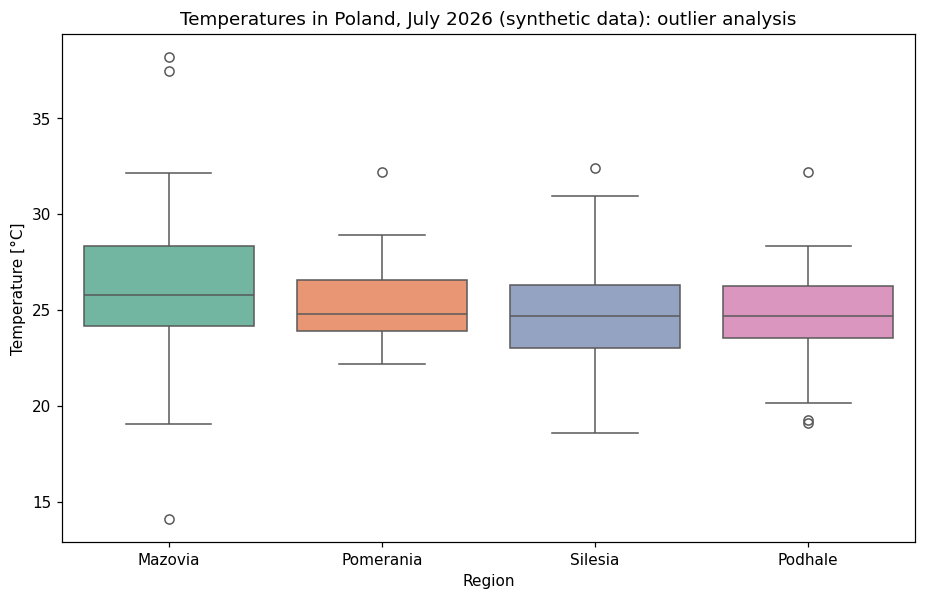

In [4]:
np.random.seed(10)
regions = ['Mazovia', 'Pomerania', 'Silesia', 'Podhale']
temp_data = []

for region in regions:
    # Generate temperatures; add outliers for one region
    temp = np.random.normal(loc=25, scale=3, size=30)
    if region == 'Mazovia':
        temp = np.append(temp, [37.5, 38.2, 14.1])  # add outliers
    temp_data.extend([(region, t) for t in temp])

df_temp = pd.DataFrame(temp_data, columns=['Region', 'Temperature'])

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_temp, x='Region', y='Temperature', palette='Set2', hue='Region', legend=False)
plt.title('Temperatures in Poland, July 2026 (synthetic data): outlier analysis')
plt.xlabel('Region')
plt.ylabel('Temperature [°C]')
plt.show()

### Violin plot: the full shape of each group

Reuses the temperature dataset from the box plot above.

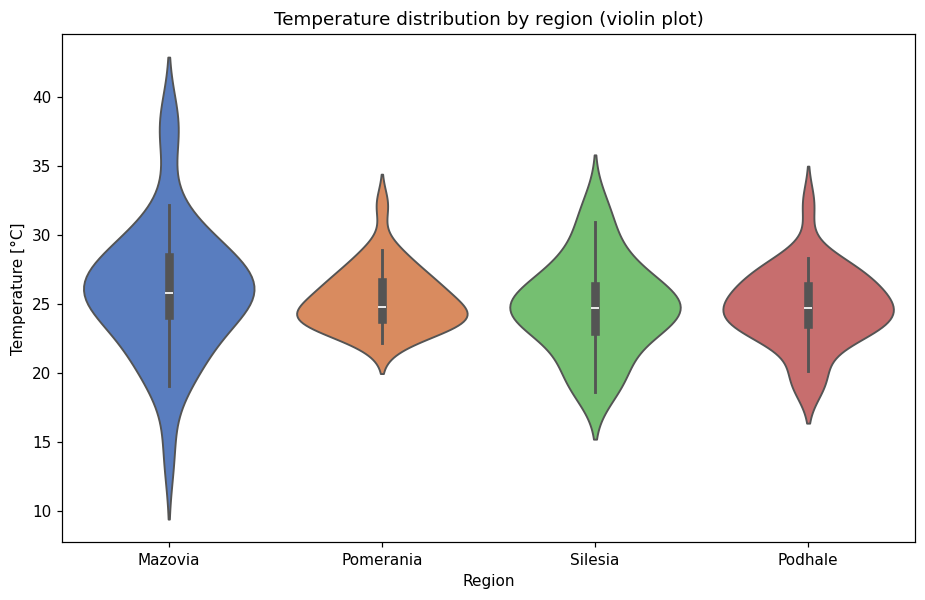

In [5]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=df_temp, x='Region', y='Temperature', palette='muted', hue='Region', legend=False)
plt.title('Temperature distribution by region (violin plot)')
plt.xlabel('Region')
plt.ylabel('Temperature [°C]')
plt.show()

## 2. Categorical comparisons

### Bar chart

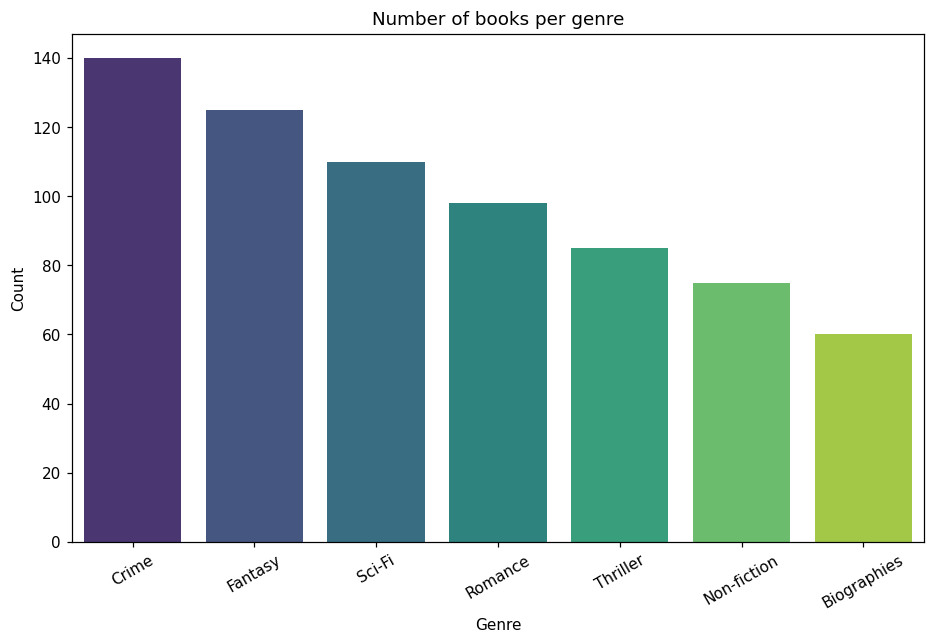

In [6]:
genres = ['Fantasy', 'Romance', 'Crime', 'Non-fiction', 'Sci-Fi', 'Thriller', 'Biographies']
counts = [125, 98, 140, 75, 110, 85, 60]

df_books = pd.DataFrame({'Genre': genres, 'Count': counts})
df_books = df_books.sort_values(by='Count', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_books, x='Genre', y='Count', palette='viridis', hue='Genre', legend=False)
plt.title('Number of books per genre')
plt.xlabel('Genre')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.show()

### Grouped bar chart

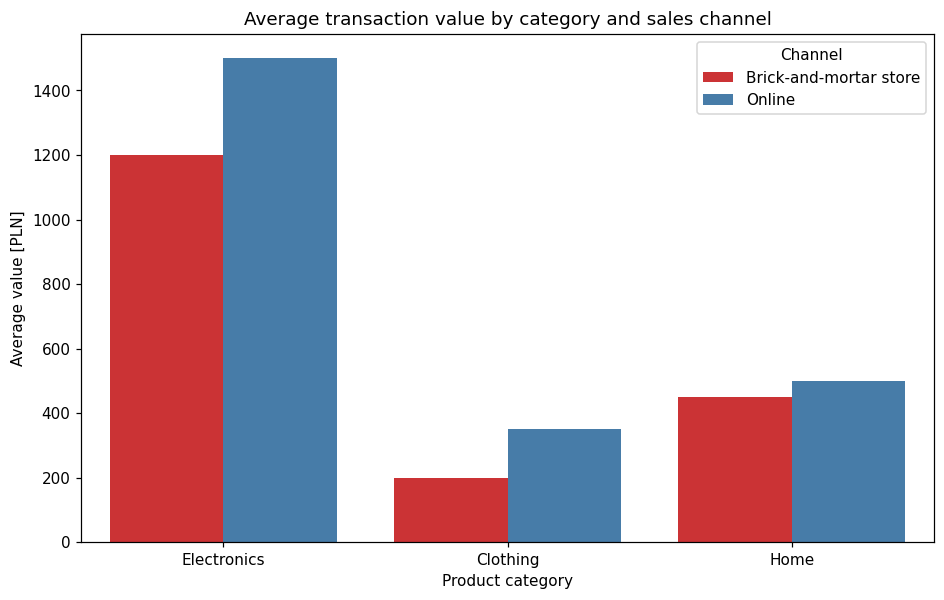

In [7]:
grouped_data = pd.DataFrame({
    'Category': ['Electronics', 'Electronics', 'Clothing', 'Clothing', 'Home', 'Home'],
    'Sales_Channel': ['Brick-and-mortar store', 'Online'] * 3,
    'Average_Value': [1200, 1500, 200, 350, 450, 500],
})

plt.figure(figsize=(10, 6))
sns.barplot(data=grouped_data, x='Category', y='Average_Value', hue='Sales_Channel', palette='Set1')
plt.title('Average transaction value by category and sales channel')
plt.xlabel('Product category')
plt.ylabel('Average value [PLN]')
plt.legend(title='Channel')
plt.show()

### Stacked bar chart

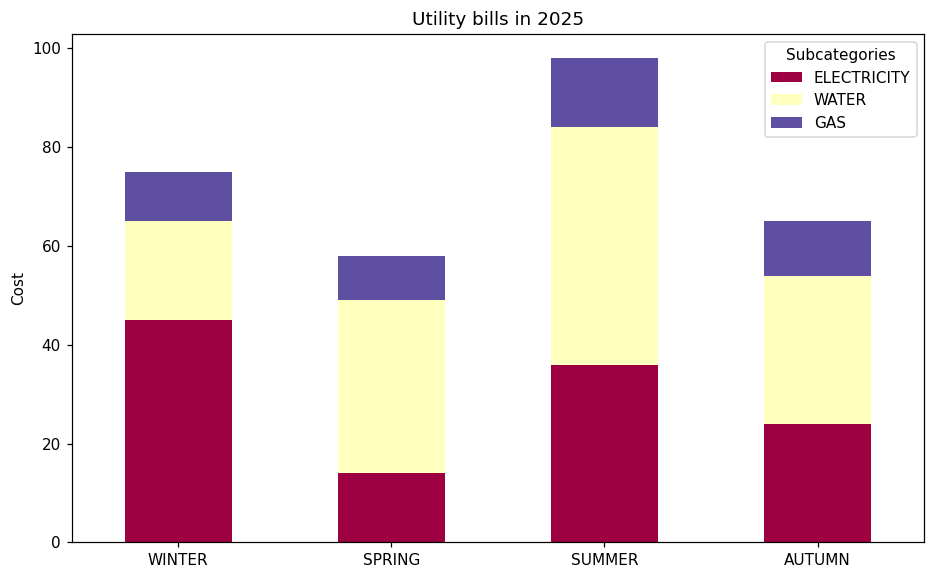

In [8]:
index = ['WINTER', 'SPRING', 'SUMMER', 'AUTUMN']
subcategory_1 = [45, 14, 36, 24]  # Electricity
subcategory_2 = [20, 35, 48, 30]  # Water
subcategory_3 = [10, 9, 14, 11]   # Gas

df_stacked = pd.DataFrame(
    {
        'ELECTRICITY': subcategory_1,
        'WATER': subcategory_2,
        'GAS': subcategory_3,
    },
    index=index,
)

ax = df_stacked.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Spectral')
plt.title('Utility bills in 2025')
plt.ylabel('Cost')
plt.xticks(rotation=0)
plt.legend(title='Subcategories')
plt.show()

## 3. Relationships

### Scatter plot

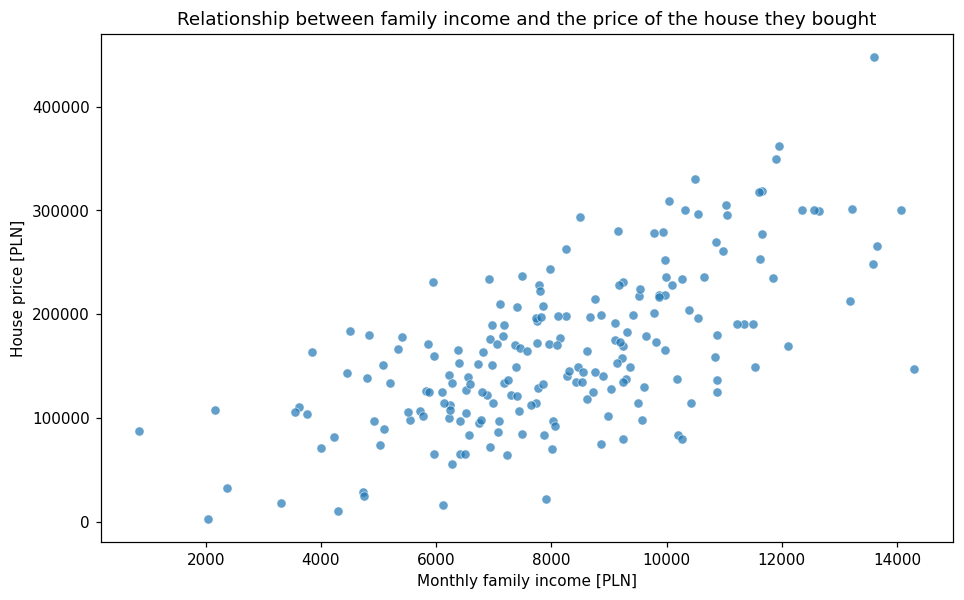

In [9]:
np.random.seed(5)
income = np.random.normal(loc=8000, scale=2500, size=200)
house_price = (income * np.random.uniform(15, 25, size=200)) + np.random.normal(0, 50000, size=200)

df_houses = pd.DataFrame({'Family_Income': income, 'House_Price': house_price})

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_houses, x='Family_Income', y='House_Price', alpha=0.7)
plt.title('Relationship between family income and the price of the house they bought')
plt.xlabel('Monthly family income [PLN]')
plt.ylabel('House price [PLN]')
plt.show()

### Scatter plot with a third dimension (`hue`)

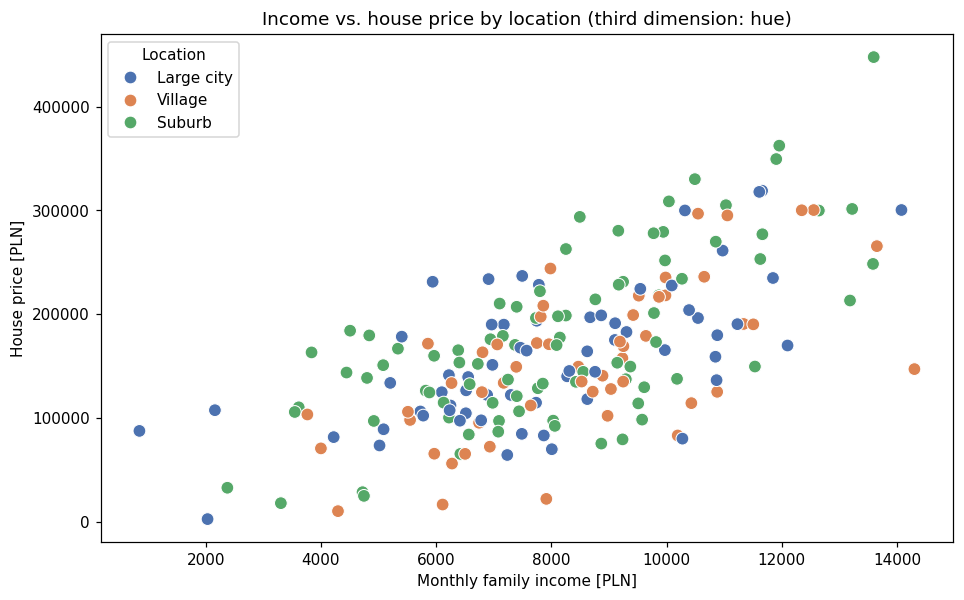

In [10]:
plt.figure(figsize=(10, 6))
df_houses['City_Size'] = np.random.choice(['Large city', 'Suburb', 'Village'], size=len(df_houses))

sns.scatterplot(
    data=df_houses,
    x='Family_Income',
    y='House_Price',
    hue='City_Size',
    palette='deep',
    s=70,
)
plt.title('Income vs. house price by location (third dimension: hue)')
plt.xlabel('Monthly family income [PLN]')
plt.ylabel('House price [PLN]')
plt.legend(title='Location')
plt.show()

### Correlation heatmap

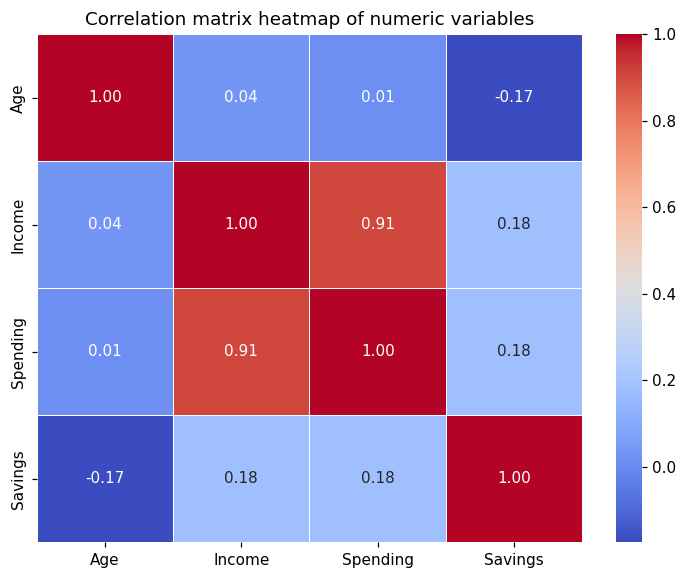

In [11]:
np.random.seed(0)
corr_data = pd.DataFrame(
    np.random.rand(100, 4), columns=['Age', 'Income', 'Spending', 'Savings']
)
corr_data['Spending'] = corr_data['Income'] * 0.7 + np.random.normal(0, 0.1, 100)

corr_matrix = corr_data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation matrix heatmap of numeric variables')
plt.show()

## 4. Time series

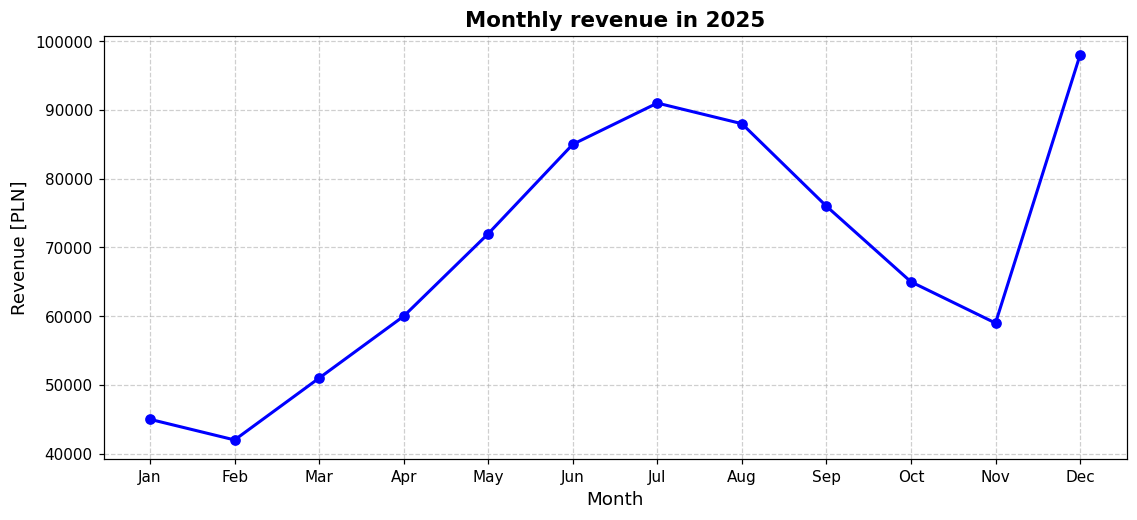

In [12]:
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
revenue = [45000, 42000, 51000, 60000, 72000, 85000, 91000, 88000, 76000, 65000, 59000, 98000]

plt.figure(figsize=(12, 5))
plt.plot(months, revenue, marker='o', color='b', linestyle='-', linewidth=2, markersize=6)
plt.title('Monthly revenue in 2025', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Revenue [PLN]', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 5. Interactive charts (Plotly Express)

### Line chart with a unified hover

In [ ]:
# Data: daily revenue of an online shop over 90 days
np.random.seed(42)
dates = pd.date_range('2026-01-01', periods=90, freq='D')
revenue_daily = 12000 + np.cumsum(np.random.normal(150, 400, 90))

df_daily = pd.DataFrame({'Date': dates, 'Revenue [PLN]': revenue_daily})

fig_line = px.line(
    df_daily, x='Date', y='Revenue [PLN]',
    title='Daily revenue of an e-commerce store over time',
    hover_data={'Revenue [PLN]': ':.2f', 'Date': '|%B %d, %Y'}
)
fig_line.update_layout(hovermode="x unified")
fig_line.show()

### Scatter matrix

In [ ]:
np.random.seed(42)
n = 120

quality = np.random.choice(['Economy', 'Standard', 'Luxury'], n)
area = np.random.randint(25, 110, n)
distance = np.random.uniform(1.0, 15.0, n)
price = area * 45 - distance * 120 + np.random.normal(1800, 300, n)

for i in range(n):
    if quality[i] == 'Luxury':
        price[i] += 1500
    elif quality[i] == 'Economy':
        price[i] -= 600

# Short column names prevent overlapping labels
df_flats = pd.DataFrame({
    'Area [m²]': area,
    'Distance [km]': np.round(distance, 1),
    'Price [PLN]': np.round(price, 0),
    'Quality': quality
})

fig_matrix = px.scatter_matrix(
    df_flats,
    dimensions=['Area [m²]', 'Distance [km]', 'Price [PLN]'],
    color='Quality',
    title='Flat attributes by quality standard',
    opacity=0.7,
    height=750,  # a tall figure forces square sub-plots
    width=950    # fixed width prevents stretching across the whole screen
)

# Show the diagonal, use smaller markers and larger margins
fig_matrix.update_traces(diagonal_visible=True, marker=dict(size=5))
fig_matrix.update_layout(margin=dict(l=110, r=40, t=60, b=60))

fig_matrix.show()

### Faceted histogram

In [ ]:
# Data: delivery time of orders from dispatch to pickup
np.random.seed(42)
n = 300
couriers = np.random.choice(['DPD', 'InPost', 'DHL'], n)
delivery_times = np.random.gamma(shape=3, scale=8, size=n)

df_delivery = pd.DataFrame({'Delivery_time_h': delivery_times, 'Courier': couriers})

fig_hist = px.histogram(
    df_delivery,
    x='Delivery_time_h',
    color='Courier',
    facet_col='Courier',
    nbins=15,
    title='Delivery time distribution by courier'
)
fig_hist.update_layout(xaxis_title="Delivery time (h)", yaxis_title="Number of parcels")
fig_hist.show()

### Bubble chart

In [ ]:
# Data: performance of individual social media campaigns
np.random.seed(42)
n = 30
budget = np.random.uniform(2000, 25000, n)
clicks = budget * np.random.uniform(0.1, 0.25, n)
revenue_campaign = budget * np.random.uniform(1.8, 4.5, n)
channel = np.random.choice(['Google Ads', 'Meta Ads', 'TikTok Ads'], n)
names = [f'Campaign #{i}' for i in range(1, n + 1)]

df_campaigns = pd.DataFrame({
    'Budget [PLN]': budget,
    'Clicks': clicks,
    'Revenue [PLN]': revenue_campaign,
    'Channel': channel,
    'Campaign': names
})

fig_bubble = px.scatter(
    df_campaigns,
    x='Budget [PLN]',
    y='Clicks',
    size='Revenue [PLN]',
    color='Channel',
    hover_name='Campaign',
    size_max=35,
    title='Campaign evaluation (X: budget, Y: clicks, size: revenue)'
)
fig_bubble.show()